# Laboratory Exercise 1: Food Delivery

City Delivery is a delivery service that brings meals from restaurants across Macedonia to the door. Its pages are a stored snapshot in `data/site`, and the setup serves them from this machine, so every request stays on the local loopback address. The orders are synthetic and describe no real restaurant, courier, or customer.

Answer each request in the cells below it, and add as many cells as you need. The laboratory test asks for values and decisions that your notebook computes, so keep every result visible, run the notebook from top to bottom before you submit it, and make sure it runs on a machine without internet access.

## Setup

The cells in this section are written already. Run them before the tasks.

In [20]:
import json
import re
import threading
from functools import partial
from http.server import SimpleHTTPRequestHandler, ThreadingHTTPServer
from pathlib import Path
from urllib.parse import parse_qs, urljoin, urlparse

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import seaborn as sns
from bs4 import BeautifulSoup, Tag
from playwright.async_api import async_playwright
from scipy import stats
from statsmodels.stats.multitest import multipletests

DATA = Path("data")
# Every random step draws from this generator, so a rerun gives the same result.
rng = np.random.default_rng(2026)

In [21]:
# The course style.
PALETTE = ["#0072B2", "#D55E00", "#009E73", "#CC79A7", "#E69F00", "#56B4E9", "#1e2a24"]
GROUND, INK, GRID = "#ffffff", "#1e2a24", "#e2e6e4"
plt.rcParams.update(
    {
        "figure.figsize": (8, 4.5),
        "figure.facecolor": GROUND,
        "figure.constrained_layout.use": True,
        "savefig.facecolor": GROUND,
        "savefig.transparent": False,
        "font.family": "sans-serif",
        "font.sans-serif": ["Archivo", "DejaVu Sans"],
        "font.size": 12,
        "text.color": INK,
        "axes.facecolor": GROUND,
        "axes.edgecolor": INK,
        "axes.labelcolor": INK,
        "axes.titleweight": "bold",
        "axes.titlelocation": "left",
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "axes.axisbelow": True,
        "axes.prop_cycle": plt.cycler(color=PALETTE),
        "grid.color": GRID,
        "xtick.color": INK,
        "ytick.color": INK,
        "legend.frameon": False,
        "image.cmap": "cividis",
    }
)
sns.set_palette(PALETTE)

In [22]:
# Every path is a file under the site directory.
class Service(SimpleHTTPRequestHandler):
    extensions_map = {
        **SimpleHTTPRequestHandler.extensions_map,
        ".html": "text/html; charset=utf-8",
    }

    def log_message(self, format: str, *args: object) -> None:
        pass


# Port 0 lets the system choose a free port, so a second running notebook never collides.
server = ThreadingHTTPServer(("127.0.0.1", 0), partial(Service, directory=DATA / "site"))
threading.Thread(target=server.serve_forever, daemon=True).start()
BASE = f"http://127.0.0.1:{server.server_port}/"
BASE

'http://127.0.0.1:52210/'

## Task 1: Collect the Orders

The service lists its delivered orders across several pages, and the first one is `catalogue/page-1.html` under `BASE`. Collect every order into a table named `orders`, with one row per order and these columns:

- `order_id`, the identifier of the order,
- `restaurant`, `cuisine`, and `city`,
- `distance` and `unit`, the distance from the restaurant to the door and the unit it is quoted in, exactly as the order states them,
- `minutes`, the minutes the delivery took,
- `slot`, `weather`, `payment`, and `rating`, the stars out of 5 that the customer gave, and
- `by_restaurant`, which is true when the restaurant delivered the order itself and false when a courier of the service did.

An order that does not state a field has a missing value in that column. Report how many orders the service lists and over how many pages they are spread.

In [23]:
def parse_order(card):
    """Turn one <article class="order"> card into a dict. A field the card does not state is missing."""
    def text(selector):
        tag = card.select_one(selector)
        return tag.get_text(strip=True) if tag else None

    delivery = text("p.delivery")
    rating = text("li.rating")
    summary = text("p.summary")
    courier = text("p.courier")
    # "A trip of 3 650 m ..." or "A trip of 5.0 km ...": digits may be grouped by spaces.
    trip = re.search(r"trip of ([\d\s.,]+?)\s*(km|m)\b", summary) if summary else None
    return {
        "order_id": int(card["data-id"]),
        "restaurant": text("h2.title"),
        "cuisine": text("span.cuisine"),
        "city": text("span.city"),
        "distance": float(re.sub(r"\s", "", trip.group(1))) if trip else np.nan,
        "unit": trip.group(2) if trip else None,
        "minutes": int(re.search(r"\d+", delivery).group()) if delivery else np.nan,
        "slot": text("li.slot"),
        "weather": text("li.weather"),
        "payment": text("li.payment"),
        "rating": int(re.search(r"Rated (\d)", rating).group(1)) if rating else np.nan,
        "by_restaurant": ("by the restaurant" in courier) if courier else None,
    }


# Follow the "Next" link from page 1 until there is none.
records, n_pages, url = [], 0, urljoin(BASE, "catalogue/page-1.html")
while url:
    response = requests.get(url, timeout=10)
    response.raise_for_status()
    soup = BeautifulSoup(response.text, "html.parser")
    records += [parse_order(card) for card in soup.select("article.order")]
    n_pages += 1
    nxt = soup.select_one("nav.pagination a.next")
    url = urljoin(url, nxt["href"]) if nxt else None

orders = pd.DataFrame(records)
print(f"The service lists {len(orders)} orders ({orders['order_id'].nunique()} distinct ids) over {n_pages} pages.")
orders.head()

The service lists 192 orders (192 distinct ids) over 16 pages.


,order_id,restaurant,cuisine,city,distance,unit,minutes,slot,weather,payment,rating,by_restaurant
0,310069,Salad Bowl,Salad,Skopje,5.0,km,23.0,Late night,Clear,Cash,5.0,False
1,283894,Pizza House,Pizza,Skopje,3650.0,m,30.0,Lunch,Clear,Card,3.0,False
2,832866,Sushi Bar,Sushi,Skopje,4700.0,m,NaN,Lunch,Rain,Cash,3.0,True
3,582431,Home Kitchen,Traditional,Skopje,2.7,km,25.0,Lunch,Rain,Card,4.0,False
4,662069,Snack Corner,Small plates,Skopje,2.4,km,26.0,Late night,Clear,Card,4.0,True


**Answer.** The service lists **192 orders** spread over **16 pages** (12 per page, which matches "192 results" on every page). Every `order_id` is distinct. Fields an order does not state (a delivery time, a rating) are kept as missing values, and the distance is stored as the number and unit exactly as quoted (`km` or `m`).

## Task 2: Add the Receipts

The home page of the service, `index.html` under `BASE`, points to a page of receipts. Collect every receipt the page holds, and add the items, the total, and the tip of each order to `orders`, so that every order appears exactly once. Name the result `df`.

Report how many receipts the page says it holds, how many you collected, and what you did about any receipt that would put an order in `df` more than once.

In [24]:
response = requests.get(urljoin(BASE, "receipts.html"), timeout=10)
response.raise_for_status()
html = response.text

# The receipts are not in the HTML table: a script holds them as a JSON array and writes the
# table after a delay. Reading that array gives the same rows without a browser.
array = re.search(r"const RECEIPTS = (\[.*?\]);", html, re.S).group(1)
receipts = pd.DataFrame(json.loads(array))

# The page's own script prints `${RECEIPTS.length} receipts`, so the page says it holds:
n_stated = len(json.loads(array))
n_collected = len(receipts)
print(f"The page says it holds {n_stated} receipts; I collected {n_collected}.")

dup_ids = receipts.loc[receipts["order_id"].duplicated(keep=False), "order_id"].unique()
print("Order ids that appear more than once:", list(dup_ids))
print(receipts[receipts["order_id"].isin(dup_ids)])
# Are the repeated receipts identical in every field? Then dropping one copy loses nothing.
print("Repeated receipts identical:", receipts[receipts["order_id"].isin(dup_ids)].drop_duplicates().shape[0] == len(dup_ids))

receipts = receipts.drop_duplicates(subset="order_id", keep="first")
print(f"After dropping the repeated copy: {len(receipts)} receipts, {receipts['order_id'].nunique()} distinct orders.")

df = orders.merge(receipts, on="order_id", how="left", validate="one_to_one")
print(f"df: {df.shape[0]} rows, {df['order_id'].is_unique=}, orders without a receipt: {df['total'].isna().sum()}")
df.head()

The page says it holds 193 receipts; I collected 193.
Order ids that appear more than once: [np.int64(510546)]
     order_id  items  total  tip
99     510546      4   1180    0
100    510546      4   1180    0
Repeated receipts identical: True
After dropping the repeated copy: 192 receipts, 192 distinct orders.
df: 192 rows, df['order_id'].is_unique=True, orders without a receipt: 0


,order_id,restaurant,cuisine,city,distance,unit,minutes,slot,weather,payment,rating,by_restaurant,items,total,tip
0,310069,Salad Bowl,Salad,Skopje,5.0,km,23.0,Late night,Clear,Cash,5.0,False,2,770,0
1,283894,Pizza House,Pizza,Skopje,3650.0,m,30.0,Lunch,Clear,Card,3.0,False,4,860,60
2,832866,Sushi Bar,Sushi,Skopje,4700.0,m,NaN,Lunch,Rain,Cash,3.0,True,2,710,0
3,582431,Home Kitchen,Traditional,Skopje,2.7,km,25.0,Lunch,Rain,Card,4.0,False,3,1240,60
4,662069,Snack Corner,Small plates,Skopje,2.4,km,26.0,Late night,Clear,Card,4.0,True,2,450,30


**Answer.** The page says it holds **193 receipts** (its own script prints `RECEIPTS.length`), and I collected **193**. The receipts are not in the HTML table: a script fills the table 500 ms after the page opens, so I read the JSON array that script uses instead of a plain table parse.

One order (`510546`) appears **twice, with identical items, total and tip**. A plain merge would put that order in `df` twice, so I kept one copy. That leaves **192 receipts for 192 orders**, and the merge (checked as one-to-one) leaves no order without a receipt.

## Task 3: Describe the Orders

Answer each request below from `df`. Support each answer with the numbers that establish it, and with a figure wherever the request asks you to show something.

### 3.1 Column Types

Give every column of `df` a type that matches what it measures. The slots have a natural order, from lunch to late night, and the type of `slot` keeps it.

In [25]:
print(df.dtypes, end="\n\n")

SLOT_ORDER = ["Lunch", "Dinner", "Late night"]
df["order_id"] = df["order_id"].astype("string")            # an identifier, not a quantity
for col in ["restaurant", "cuisine", "city", "unit", "weather", "payment"]:
    df[col] = df[col].astype("category")                    # nominal labels
df["slot"] = pd.Categorical(df["slot"], categories=SLOT_ORDER, ordered=True)  # ordered labels
df["distance"] = df["distance"].astype("float64")           # measured, continuous
df["minutes"] = df["minutes"].astype("Int64")               # whole minutes, may be missing
df["rating"] = df["rating"].astype("Int64")                 # stars 1-5 (ordinal), may be missing
df["by_restaurant"] = df["by_restaurant"].astype("bool")    # yes/no
for col in ["items", "total", "tip"]:
    df[col] = df[col].astype("int64")                       # counts / whole MKD amounts

print(df.dtypes)
print("slot order:", list(df["slot"].cat.categories), "| ordered:", df["slot"].cat.ordered)

order_id           int64
restaurant           str
cuisine              str
city                 str
distance         float64
unit                 str
minutes          float64
slot                 str
weather              str
payment              str
rating           float64
by_restaurant       bool
items              int64
total              int64
tip                int64
dtype: object

order_id           string
restaurant       category
cuisine          category
city             category
distance          float64
unit             category
minutes             Int64
slot             category
weather          category
payment          category
rating              Int64
by_restaurant        bool
items               int64
total               int64
tip                 int64
dtype: object
slot order: ['Lunch', 'Dinner', 'Late night'] | ordered: True


**Types chosen.**

| column | type | why |
|---|---|---|
| `order_id` | string | an identifier, not a quantity |
| `restaurant`, `cuisine`, `city`, `unit`, `weather`, `payment` | category | nominal labels |
| `slot` | ordered category (Lunch < Dinner < Late night) | labels with a natural order |
| `distance`, `distance_km` | float | measured, continuous |
| `minutes`, `rating` | nullable integer (`Int64`) | whole numbers that can be missing |
| `by_restaurant` | bool | yes / no |
| `items`, `total`, `tip` | integer | counts and whole MKD amounts |

### 3.2 What Is Missing

Count the missing values in each column, show where they fall, and find out whether the absence of a value depends on another column.

               missing  share
order_id             0  0.000
restaurant           0  0.000
cuisine              0  0.000
city                 0  0.000
distance             0  0.000
unit                 0  0.000
minutes             42  0.219
slot                 0  0.000
weather              0  0.000
payment              0  0.000
rating              24  0.125
by_restaurant        0  0.000
items                0  0.000
total                0  0.000
tip                  0  0.000



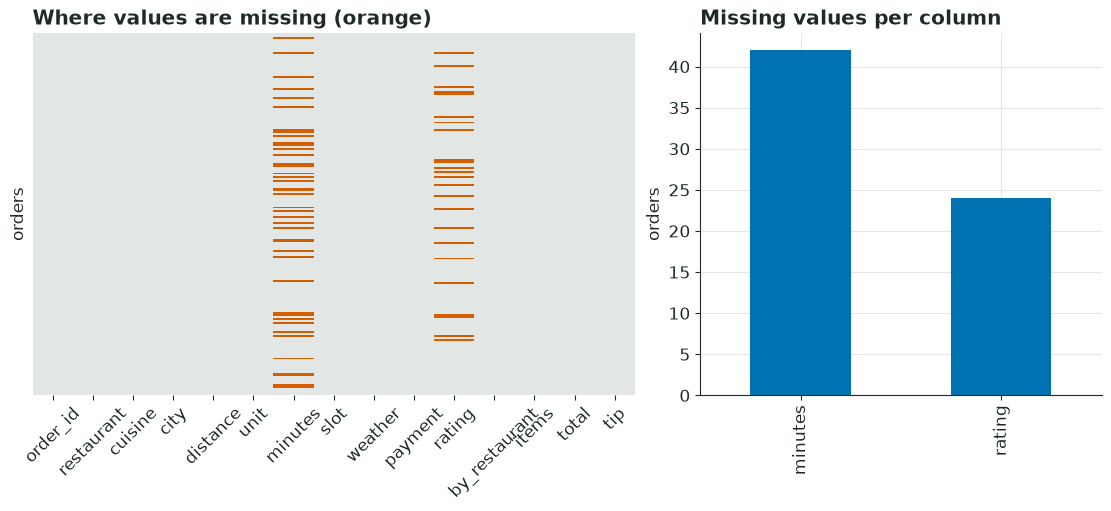

missing in compared with                                       test      p  p_holm  dependent (5 %)
   minutes by_restaurant                               Fisher exact 0.0000     0.0             True
   minutes       cuisine                                 chi-square 0.1100     1.0            False
   minutes           tip                             Mann-Whitney U 0.2384     1.0            False
   minutes      distance                             Mann-Whitney U 0.2424     1.0            False
   minutes       payment                               Fisher exact 0.3287     1.0            False
   minutes         total                             Mann-Whitney U 0.3807     1.0            False
   minutes          city                                 chi-square 0.4732     1.0            False
   minutes         items                             Mann-Whitney U 0.5001     1.0            False
   minutes        rating Fisher exact (is the other value missing?) 0.7918     1.0            False


In [26]:
missing = df.isna().sum()
print(pd.DataFrame({"missing": missing, "share": (missing / len(df)).round(3)}), end="\n\n")

fig, axes = plt.subplots(1, 2, figsize=(11, 5), gridspec_kw={"width_ratios": [3, 2]})
sns.heatmap(df.isna(), cbar=False, yticklabels=False, cmap=["#e2e6e4", PALETTE[1]], ax=axes[0])
axes[0].set(title="Where values are missing (orange)", xlabel="", ylabel="orders")
axes[0].tick_params(axis="x", rotation=45)
axes[0].grid(False)
missing[missing > 0].plot.bar(color=PALETTE[0], ax=axes[1])
axes[1].set(title="Missing values per column", ylabel="orders")
plt.show()

# Does missingness depend on another column? One test per (indicator, column), then a Holm correction.
df["_minutes_missing"] = df["minutes"].isna()
df["_rating_missing"] = df["rating"].isna()
tests = []
for flag, col_name in [("_minutes_missing", "minutes"), ("_rating_missing", "rating")]:
    others = [c for c in df.columns if c not in {"order_id", "restaurant", "_minutes_missing", "_rating_missing", col_name}]
    for other in others:
        if other == "minutes" or other == "rating":
            other_flag = "_rating_missing" if other == "rating" else "_minutes_missing"
            table = pd.crosstab(df[flag], df[other_flag])
            test = "Fisher exact (is the other value missing?)"
            p = stats.fisher_exact(table)[1]
        elif pd.api.types.is_numeric_dtype(df[other]) and not pd.api.types.is_bool_dtype(df[other]):
            a = df.loc[df[flag], other].astype(float)
            b = df.loc[~df[flag], other].astype(float)
            test, p = "Mann-Whitney U", stats.mannwhitneyu(a, b).pvalue
        else:
            table = pd.crosstab(df[flag], df[other])
            if table.shape == (2, 2):
                test, p = "Fisher exact", stats.fisher_exact(table)[1]
            else:
                test, p = "chi-square", stats.chi2_contingency(table)[1]
        tests.append({"missing in": col_name, "compared with": other, "test": test, "p": p})

tests = pd.DataFrame(tests)
tests["p_holm"] = np.nan
for name, part in tests.groupby("missing in"):
    tests.loc[part.index, "p_holm"] = multipletests(part["p"], method="holm")[1]
tests["dependent (5 %)"] = tests["p_holm"] < 0.05
print(tests.sort_values(["missing in", "p"]).round(4).to_string(index=False))

print()
print(pd.crosstab(df["by_restaurant"], df["_minutes_missing"], margins=True).rename(columns={False: "time stated", True: "time missing"}))
print(df.groupby("by_restaurant")["_minutes_missing"].mean().round(3).rename("share of missing delivery times"))
df = df.drop(columns=["_minutes_missing", "_rating_missing"])

**Answer.** Only two columns have missing values: **`minutes` (42 orders, 21.9 %)** and **`rating` (24 orders, 12.5 %)**; all other columns are complete.

- **`minutes` depends on `by_restaurant`.** The delivery time is missing for 32 of the 50 orders (**64 %**) that the restaurant delivered itself, but for only 10 of the 142 (**7 %**) delivered by a courier (Fisher exact test, p-value below 0.0001 and still significant after a Holm correction for the 12 comparisons). No other column shows a dependence after the correction.
- **`rating` shows no dependence** on any other column (smallest corrected p-value is 1.0), so it looks like values that are missing without a pattern.

So the delivery times are not missing at random: restaurant-delivered orders are underrepresented in everything that uses `minutes`.

### 3.3 Distances in Two Units

Some orders quote the distance in metres and others in kilometres. Compare the quoted distances within each unit, then add a column `distance_km` that states every distance in kilometres.

      count     mean      std     min     25%     50%     75%     max
unit                                                                 
km    162.0     3.23     1.28     1.3     2.3     2.9     4.1     8.0
m      30.0  2498.33  1066.78  1200.0  1650.0  2375.0  2887.5  5350.0



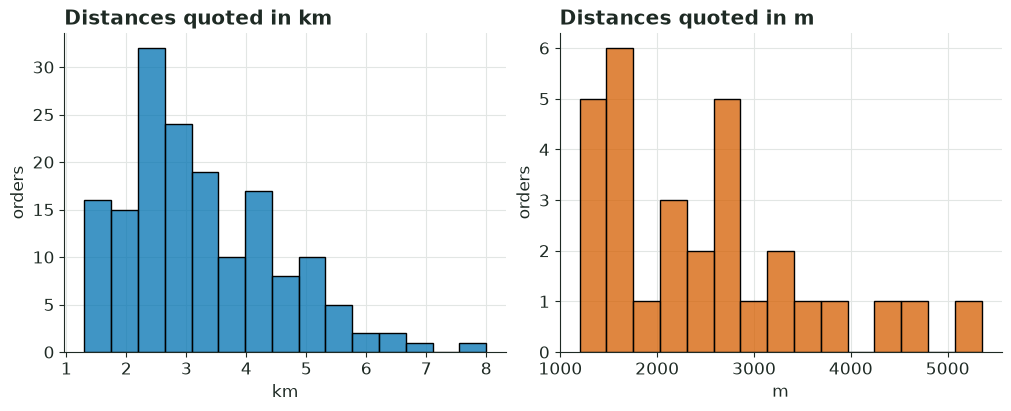

      count  mean   std  min   25%   50%   75%   max
unit                                                
km    162.0  3.23  1.28  1.3  2.30  2.90  4.10  8.00
m      30.0  2.50  1.07  1.2  1.65  2.38  2.89  5.35

All distances in km: min 1.20, max 8.00, median 2.83
Orders quoted in m vs km, same scale: Mann-Whitney U p = 0.0022


In [27]:
by_unit = df.groupby("unit", observed=True)["distance"].describe().round(2)
print(by_unit, end="\n\n")

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (unit, color) in zip(axes, [("km", PALETTE[0]), ("m", PALETTE[1])]):
    sns.histplot(df.loc[df["unit"] == unit, "distance"], bins=15, color=color, ax=ax)
    ax.set(title=f"Distances quoted in {unit}", xlabel=unit, ylabel="orders")
plt.show()

df["distance_km"] = np.where(df["unit"] == "m", df["distance"] / 1000, df["distance"])
print(df.groupby("unit", observed=True)["distance_km"].describe().round(2), end="\n\n")
u = stats.mannwhitneyu(df.loc[df["unit"] == "m", "distance_km"], df.loc[df["unit"] == "km", "distance_km"])
print(f"All distances in km: min {df['distance_km'].min():.2f}, max {df['distance_km'].max():.2f}, median {df['distance_km'].median():.2f}")
print(f"Orders quoted in m vs km, same scale: Mann-Whitney U p = {u.pvalue:.4f}")

**Answer.** The two units are on different scales, so the raw `distance` column cannot be compared or averaged: orders quoted in **km** run from 1.3 to 8.0 (median 2.9), orders quoted in **m** from 1 200 to 5 350 (median 2 375). The `distance_km` column divides the metre values by 1 000.

After the conversion both groups share one scale (1.2 to 8.0 km, median 2.83 km). The orders quoted in metres are somewhat shorter on average (2.50 km against 3.23 km; Mann-Whitney p = 0.002), which is plausible if the service quotes short trips in metres.

### 3.4 The Delivery Time

Describe the delivery time by its centre, its spread, and the shape of its distribution, and show the distribution. Decide which summary of the centre describes a typical order better.

n                         150.00
mean                       29.78
median                     27.00
std                        10.28
IQR                        11.00
MAD (median abs. dev.)      5.00
min                        12.00
max                        72.00
skewness                    1.41
excess kurtosis             2.42
dtype: float64

Shapiro-Wilk normality test p = 4.80e-09
Share of orders above mean + 2 SD: 0.060


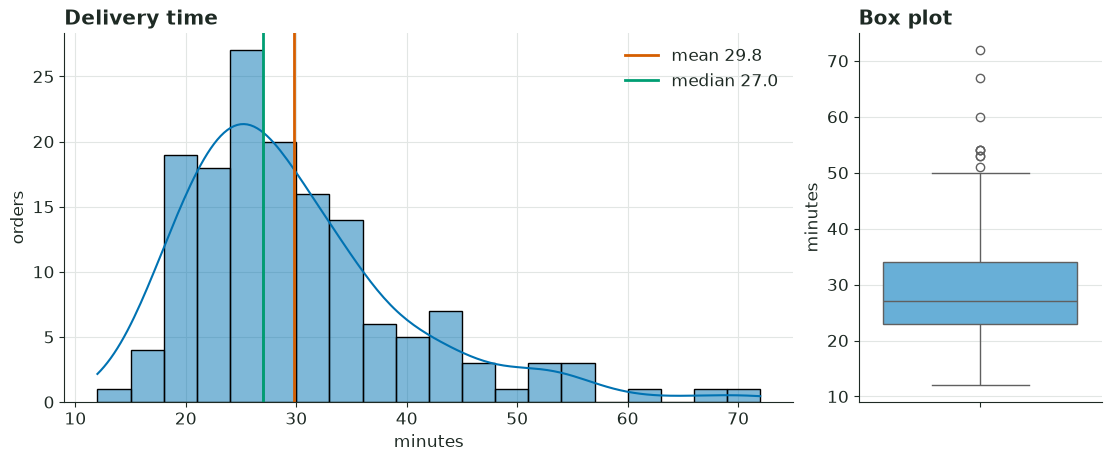

In [28]:
t = df["minutes"].dropna().astype(float)
q1, med, q3 = t.quantile([0.25, 0.5, 0.75])
summary = pd.Series({
    "n": len(t), "mean": t.mean(), "median": med, "std": t.std(), "IQR": q3 - q1,
    "MAD (median abs. dev.)": stats.median_abs_deviation(t), "min": t.min(), "max": t.max(),
    "skewness": stats.skew(t), "excess kurtosis": stats.kurtosis(t),
}).round(2)
print(summary, end="\n\n")
print("Shapiro-Wilk normality test p =", f"{stats.shapiro(t).pvalue:.2e}")
print("Share of orders above mean + 2 SD:", f"{(t > t.mean() + 2 * t.std()).mean():.3f}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.5), gridspec_kw={"width_ratios": [3, 1]})
sns.histplot(t, bins=20, kde=True, color=PALETTE[0], ax=ax1)
ax1.axvline(t.mean(), color=PALETTE[1], lw=2, label=f"mean {t.mean():.1f}")
ax1.axvline(med, color=PALETTE[2], lw=2, label=f"median {med:.1f}")
ax1.set(title="Delivery time", xlabel="minutes", ylabel="orders")
ax1.legend()
sns.boxplot(y=t, color=PALETTE[5], ax=ax2)
ax2.set(title="Box plot", ylabel="minutes")
plt.show()

**Answer (150 orders that state a time).**

- **Centre:** mean **29.8** minutes, median **27** minutes.
- **Spread:** standard deviation 10.3, IQR 11 (23 to 34), range 12 to 72.
- **Shape:** clearly **right-skewed** (skewness 1.41, heavy right tail, excess kurtosis 2.4). Shapiro-Wilk rejects normality (p about 5e-9).

Because a few very slow deliveries pull the mean above the bulk of the data, the **median (27 min) describes a typical order better** than the mean (29.8 min).

### 3.5 Delivery Time by Slot

Compare the delivery time across the slots.

             n   mean  median    std     q1    q3
slot                                             
Lunch       45  28.93    27.0   9.61   23.0  31.0
Dinner      61  30.75    28.0    9.5   24.0  35.0
Late night  44   29.3    26.0  11.99  22.75  32.0



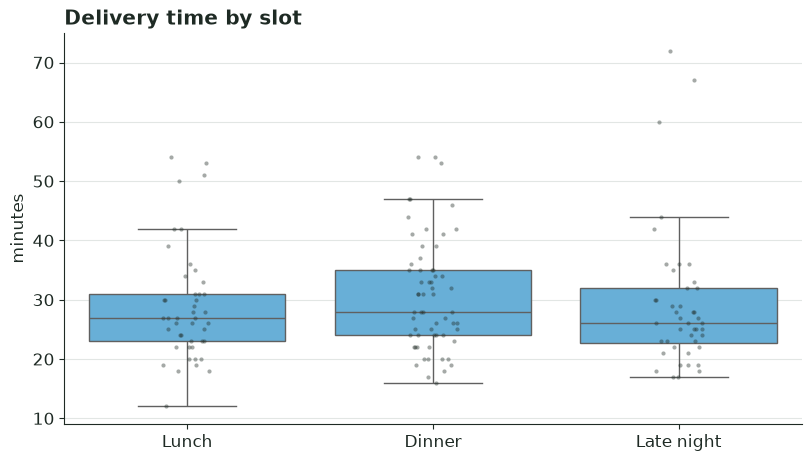

Kruskal-Wallis across slots: p = 0.3258


In [29]:
by_slot = df.groupby("slot", observed=True)["minutes"].agg(
    n=lambda s: s.notna().sum(),
    mean=lambda s: s.dropna().astype(float).mean(),
    median=lambda s: s.dropna().astype(float).median(),
    std=lambda s: s.dropna().astype(float).std(),
    q1=lambda s: s.dropna().astype(float).quantile(0.25),
    q3=lambda s: s.dropna().astype(float).quantile(0.75),
).round(2)
print(by_slot, end="\n\n")

plot_df = df.dropna(subset=["minutes"]).assign(minutes=lambda d: d["minutes"].astype(float))
fig, ax = plt.subplots()
sns.boxplot(data=plot_df, x="slot", y="minutes", order=SLOT_ORDER, color=PALETTE[5], showfliers=False, ax=ax)
sns.stripplot(data=plot_df, x="slot", y="minutes", order=SLOT_ORDER, color=INK, alpha=0.4, size=3, ax=ax)
ax.set(title="Delivery time by slot", xlabel="", ylabel="minutes")
plt.show()

groups = [g["minutes"].to_numpy() for _, g in plot_df.groupby("slot", observed=True)]
print("Kruskal-Wallis across slots: p =", f"{stats.kruskal(*groups).pvalue:.4f}")

**Answer.** The slots look alike. Median delivery time is 27 min at lunch, 28 at dinner and 26 late at night (means 28.9, 30.8 and 29.3). Late night has the widest spread (SD 12.0 against about 9.5). A Kruskal-Wallis test finds no difference between the slots (p = 0.33).

### 3.6 Orders by City

Show how the orders are spread across the cities, and give the share of orders in each city.

          orders  share  share %
city                            
Skopje        99  0.516     51.6
Tetovo        24  0.125     12.5
Kumanovo      22  0.115     11.5
Bitola        18  0.094      9.4
Ohrid         15  0.078      7.8
Prilep        14  0.073      7.3



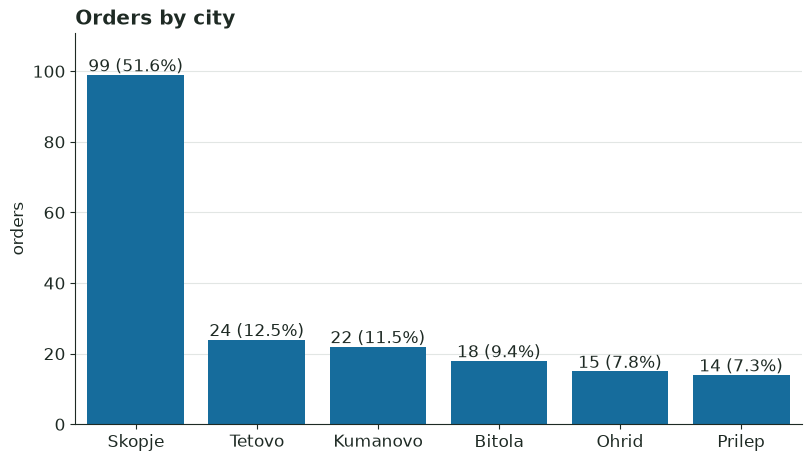

In [30]:
by_city = df["city"].value_counts()
share = (by_city / len(df)).round(3)
print(pd.DataFrame({"orders": by_city, "share": share, "share %": (share * 100).round(1)}), end="\n\n")

fig, ax = plt.subplots()
sns.barplot(x=by_city.index.astype(str), y=by_city.values, color=PALETTE[0], ax=ax)
for i, (n, s) in enumerate(zip(by_city.values, share.values)):
    ax.text(i, n + 1, f"{n} ({s:.1%})", ha="center")
ax.set(title="Orders by city", xlabel="", ylabel="orders", ylim=(0, by_city.max() * 1.12))
plt.show()

**Answer.** Half of the orders come from the capital: **Skopje 99 (51.6 %)**, Tetovo 24 (12.5 %), Kumanovo 22 (11.5 %), Bitola 18 (9.4 %), Ohrid 15 (7.8 %), Prilep 14 (7.3 %).

### 3.7 Items and Total

Show how the number of items and the total of an order move together, and measure how strongly they do. Decide whether the relationship is close to a straight line.

Pearson r = 0.881 (R^2 = 0.775), Spearman rho = 0.869
Straight-line fit: total = 2 + 292 * items
       count    mean    std
items                      
1         29   295.2   72.9
2         48   615.4  156.0
3         59   864.2  233.8
4         27  1138.5  251.1
5         21  1441.4  360.9
6          3  1446.7   50.3
7          4  2255.0  202.4
8          1  2840.0    NaN

Residual spread (SD) for few items: 131, for many items: 351


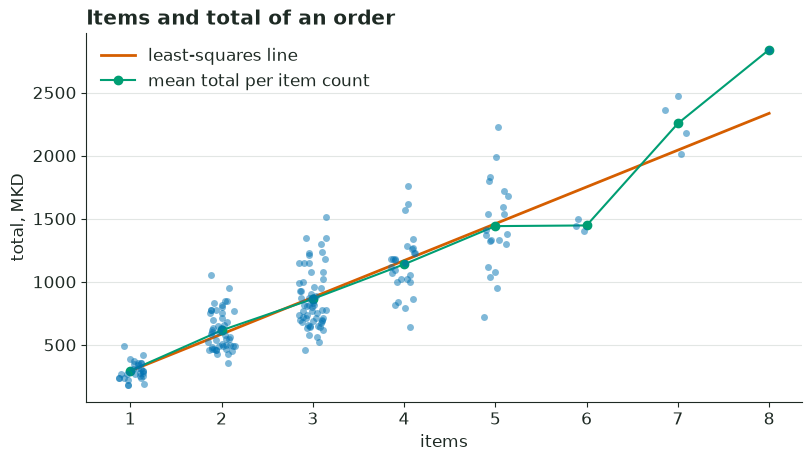

In [31]:
pearson = stats.pearsonr(df["items"], df["total"])
spearman = stats.spearmanr(df["items"], df["total"])
fit = stats.linregress(df["items"], df["total"])
print(f"Pearson r = {pearson.statistic:.3f} (R^2 = {pearson.statistic**2:.3f}), Spearman rho = {spearman.statistic:.3f}")
print(f"Straight-line fit: total = {fit.intercept:.0f} + {fit.slope:.0f} * items")
print(df.groupby("items")["total"].agg(["count", "mean", "std"]).round(1), end="\n\n")

# A line with the means per item count: if they follow the fitted line, the shape is linear.
resid = df["total"] - (fit.intercept + fit.slope * df["items"])
print(f"Residual spread (SD) for few items: {resid[df['items'] <= 2].std():.0f}, for many items: {resid[df['items'] >= 5].std():.0f}")

fig, ax = plt.subplots()
sns.stripplot(data=df, x="items", y="total", color=PALETTE[0], alpha=0.5, jitter=0.15, ax=ax)
xs = np.arange(df["items"].min(), df["items"].max() + 1)
ax.plot(xs - df["items"].min(), fit.intercept + fit.slope * xs, color=PALETTE[1], lw=2, label="least-squares line")
ax.plot(df.groupby("items")["total"].mean().reset_index(drop=True), color=PALETTE[2], marker="o", lw=1.5, label="mean total per item count")
ax.set(title="Items and total of an order", xlabel="items", ylabel="total, MKD")
ax.legend()
plt.show()

**Answer.** Items and total move strongly together: **Pearson r = 0.88** (R-squared 0.78) and **Spearman rho = 0.87**. Each extra item adds about **292 MKD** on average, and the mean total per item count follows the fitted line closely.

The relationship is **close to a straight line in its trend**, but not a clean one: the scatter around the line widens as orders get bigger (residual SD about 131 MKD for 1 to 2 items against 351 MKD for 5 or more), so the line predicts small orders much more tightly than large ones.

### 3.8 Every Pair of Numeric Columns

Show how strongly every pair of numeric columns moves together, measured by the Spearman correlation, and name the pair that moves together most strongly.

             distance_km  minutes  rating  items  total   tip
distance_km         1.00     0.59   -0.31  -0.00   0.00  0.02
minutes             0.59     1.00   -0.42  -0.07  -0.04  0.07
rating             -0.31    -0.42    1.00   0.08   0.09 -0.04
items              -0.00    -0.07    0.08   1.00   0.87  0.42
total               0.00    -0.04    0.09   0.87   1.00  0.46
tip                 0.02     0.07   -0.04   0.42   0.46  1.00



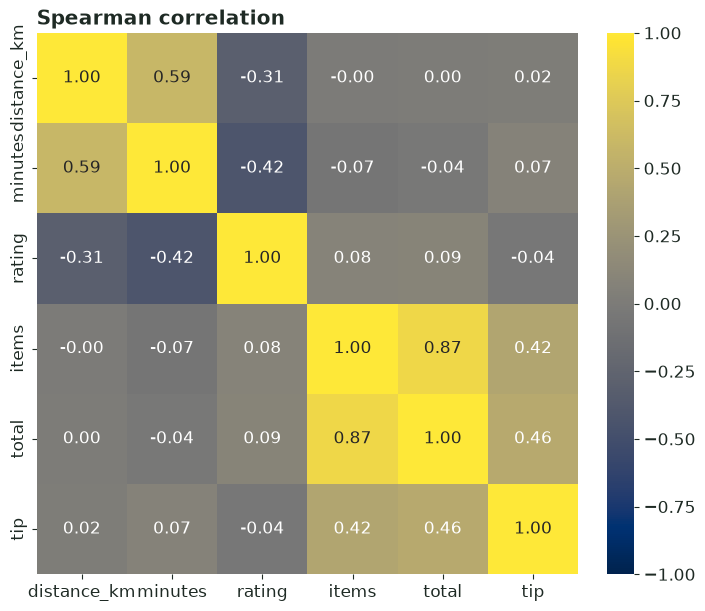

Pairs by strength:
items        total      0.869
distance_km  minutes    0.590
total        tip        0.463
items        tip        0.423
minutes      rating    -0.415
dtype: float64

Strongest pair: items and total, rho = 0.869


In [32]:
numeric = ["distance_km", "minutes", "rating", "items", "total", "tip"]
num_df = df[numeric].astype(float)
rho = num_df.corr(method="spearman")      # pairwise: a pair uses the orders that state both values
print(rho.round(2), end="\n\n")

fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(rho, annot=True, fmt=".2f", cmap="cividis", vmin=-1, vmax=1, square=True, ax=ax)
ax.set(title="Spearman correlation")
ax.grid(False)
plt.show()

pairs = rho.where(np.triu(np.ones(rho.shape, dtype=bool), k=1)).stack()
strongest = pairs.abs().idxmax()
print("Pairs by strength:")
print(pairs.reindex(pairs.abs().sort_values(ascending=False).index).round(3).head(5))
print(f"\nStrongest pair: {strongest[0]} and {strongest[1]}, rho = {pairs[strongest]:.3f}")

**Answer.** The pair that moves together most strongly is **`items` and `total`** (Spearman rho = **0.87**). The next ones are `distance_km` with `minutes` (0.59, longer trips take longer), `total` with `tip` (0.46) and `rating` with `minutes` (-0.42, slower deliveries get lower ratings).

### 3.9 Delivery Time by City and Slot

Find the combination of city and slot with the highest median delivery time, counting only the combinations with at least three orders that state a delivery time.

In [33]:
cell = (
    df.dropna(subset=["minutes"])
    .assign(minutes=lambda d: d["minutes"].astype(float))
    .groupby(["city", "slot"], observed=True)["minutes"]
    .agg(n="count", median="median")
    .reset_index()
)
eligible = cell[cell["n"] >= 3].sort_values("median", ascending=False)
print(eligible.head(8).to_string(index=False))
best = eligible.iloc[0]
print(f"\nHighest median delivery time: {best['city']} / {best['slot']}, {best['median']:.1f} minutes ({int(best['n'])} orders)")
print(f"Combinations: {len(cell)}, with at least 3 timed orders: {len(eligible)}")

    city       slot  n  median
  Prilep     Dinner  5    35.0
  Tetovo      Lunch  3    34.0
Kumanovo     Dinner  6    33.5
  Tetovo Late night  5    32.0
   Ohrid Late night  3    32.0
Kumanovo      Lunch  8    29.5
  Tetovo     Dinner  8    29.5
  Bitola      Lunch  4    28.5

Highest median delivery time: Prilep / Dinner, 35.0 minutes (5 orders)
Combinations: 18, with at least 3 timed orders: 17


**Answer.** Among the 17 city and slot combinations with at least three timed orders, the highest median delivery time is **Prilep at dinner, 35 minutes** (5 orders). Tetovo at lunch (34, only 3 orders) and Kumanovo at dinner (33.5) follow. With so few orders per combination this is a description of the sample, not a firm finding.

## Task 4: Delivery Times

Use a significance level of 5 % and a confidence level of 95 % for every decision and every range in this task and the next. For each question, state the decision and give the range beside it. The questions of this task concern the orders that state a delivery time.

### 4.1 The Advertised Time

The home page states an average delivery time. Decide whether the average delivery time of the orders differs from that statement, and give a range for the average delivery time.

In [34]:
t = df["minutes"].dropna().astype(float)
ADVERTISED = 28    # "Your food arrives in 28 minutes on average." (home page)
ALPHA = 0.05

# Read the figure from the home page rather than typing it.
home = requests.get(urljoin(BASE, "index.html"), timeout=10).text
assert f"{ADVERTISED} minutes on average" in home

res = stats.ttest_1samp(t, ADVERTISED)
ci = res.confidence_interval(confidence_level=1 - ALPHA)
print(f"n = {len(t)}, mean = {t.mean():.2f} minutes, SD = {t.std():.2f}")
print(f"One-sample t-test against {ADVERTISED}: t = {res.statistic:.3f}, df = {len(t) - 1}, p = {res.pvalue:.4f}")
print(f"95 % confidence interval for the average delivery time: [{ci.low:.2f}, {ci.high:.2f}] minutes")
print("Decision:", "reject H0 - the average differs from the statement" if res.pvalue < ALPHA else "do not reject H0 - no evidence the average differs from the statement")
print(f"The advertised {ADVERTISED} lies {'inside' if ci.low <= ADVERTISED <= ci.high else 'outside'} the interval.")

n = 150, mean = 29.78 minutes, SD = 10.28
One-sample t-test against 28: t = 2.120, df = 149, p = 0.0357
95 % confidence interval for the average delivery time: [28.12, 31.44] minutes
Decision: reject H0 - the average differs from the statement
The advertised 28 lies outside the interval.


**Answer.** The home page states 28 minutes on average. The orders that state a time average **29.8 minutes**.

- **Decision:** the one-sample t-test gives p = 0.036, below 5 %, so we **reject** the statement: the average delivery time **differs** from 28 minutes.
- **Range:** the 95 % confidence interval for the average delivery time is **[28.1, 31.4] minutes**, which just excludes 28.

Caution: 42 orders have no delivery time, mostly restaurant-delivered ones (see 3.2), so this describes the orders that state a time.

### 4.2 Rain and Clear Weather

Decide whether the orders delivered in rain and in clear weather differ in their average delivery time, and give a range for the difference, taken as rain minus clear.

In [35]:
timed = df.dropna(subset=["minutes"]).assign(minutes=lambda d: d["minutes"].astype(float))
rain = timed.loc[timed["weather"] == "Rain", "minutes"]
clear = timed.loc[timed["weather"] == "Clear", "minutes"]
print(f"Rain: n = {len(rain)}, mean = {rain.mean():.2f}, SD = {rain.std():.2f}")
print(f"Clear: n = {len(clear)}, mean = {clear.mean():.2f}, SD = {clear.std():.2f}")

# Welch's t-test: the two groups have different sizes and spreads.
res = stats.ttest_ind(rain, clear, equal_var=False)
ci = res.confidence_interval(confidence_level=0.95)     # rain minus clear
print(f"Welch t-test: t = {res.statistic:.3f}, df = {res.df:.1f}, p = {res.pvalue:.2e}")
print(f"Difference (rain - clear) = {rain.mean() - clear.mean():.2f} minutes, 95 % CI [{ci.low:.2f}, {ci.high:.2f}]")
print("Decision:", "reject H0 - the averages differ" if res.pvalue < 0.05 else "do not reject H0 - no evidence the averages differ")

# Robustness: the times are right-skewed, so check with a rank test too.
print(f"Mann-Whitney U (rank-based check): p = {stats.mannwhitneyu(rain, clear).pvalue:.2e}")

Rain: n = 45, mean = 32.78, SD = 11.52
Clear: n = 105, mean = 28.50, SD = 9.48
Welch t-test: t = 2.196, df = 70.7, p = 3.14e-02
Difference (rain - clear) = 4.28 minutes, 95 % CI [0.39, 8.17]
Decision: reject H0 - the averages differ
Mann-Whitney U (rank-based check): p = 2.05e-02


**Answer.** Mean delivery time is 32.8 min in rain (45 orders) and 28.5 min in clear weather (105 orders).

- **Decision:** Welch's t-test gives p = 0.031, below 5 %, so we **reject** equal averages: rain and clear weather **differ**. A rank-based check agrees (p = 0.021).
- **Range:** the 95 % confidence interval for the difference (rain minus clear) is **[0.4, 8.2] minutes**. Rain is slower, by about 4.3 minutes on average, but the lower end of the range is close to zero.

## Task 5: Slots and Payments

The questions of this task concern all orders.

### 5.1 Payment by Slot

Decide whether the payment method depends on the slot of an order, and give a range for the share of cash payments in each slot, using a percentile bootstrap.

payment     Card  Cash
slot                  
Lunch         49     7
Dinner        57    22
Late night    34    23

payment     Card %  Cash %
slot                      
Lunch         87.5    12.5
Dinner        72.2    27.8
Late night    59.6    40.4

Chi-square test of independence: chi2 = 11.135, df = 2, p = 0.0038
Smallest expected count = 15.2 (the test needs about 5 or more)
Decision: reject H0 - payment depends on the slot
      slot  orders  cash share  ci low  ci high
     Lunch      56       0.125   0.054    0.214
    Dinner      79       0.278   0.190    0.380
Late night      57       0.404   0.281    0.526


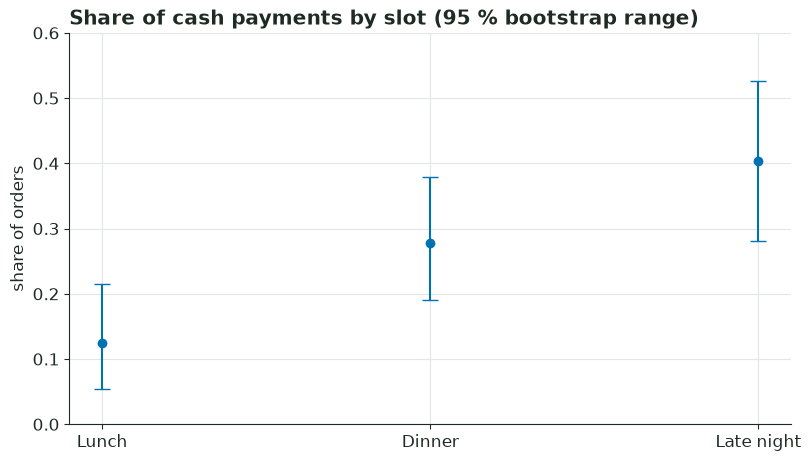

In [36]:
table = pd.crosstab(df["slot"], df["payment"]).loc[SLOT_ORDER]
print(table, end="\n\n")
print((table.div(table.sum(axis=1), axis=0) * 100).round(1).rename(columns=lambda c: f"{c} %"), end="\n\n")

chi2, p, dof, expected = stats.chi2_contingency(table)
print(f"Chi-square test of independence: chi2 = {chi2:.3f}, df = {dof}, p = {p:.4f}")
print(f"Smallest expected count = {expected.min():.1f} (the test needs about 5 or more)")
print("Decision:", "reject H0 - payment depends on the slot" if p < 0.05 else "do not reject H0 - no evidence that payment depends on the slot")

# Percentile bootstrap for the share of cash payments in each slot.
B = 10_000
rows = []
for slot in SLOT_ORDER:
    cash = (df.loc[df["slot"] == slot, "payment"] == "Cash").to_numpy().astype(float)
    boot = cash[rng.integers(0, len(cash), size=(B, len(cash)))].mean(axis=1)
    lo, hi = np.percentile(boot, [2.5, 97.5])
    rows.append({"slot": slot, "orders": len(cash), "cash share": cash.mean(), "ci low": lo, "ci high": hi})
cash_ci = pd.DataFrame(rows)
print(cash_ci.round(3).to_string(index=False))

fig, ax = plt.subplots()
ax.errorbar(cash_ci["slot"], cash_ci["cash share"], yerr=[cash_ci["cash share"] - cash_ci["ci low"], cash_ci["ci high"] - cash_ci["cash share"]],
            fmt="o", color=PALETTE[0], capsize=6)
ax.set(title="Share of cash payments by slot (95 % bootstrap range)", ylabel="share of orders", ylim=(0, 0.6))
plt.show()

**Answer.** The share of cash payments rises from lunch to late night.

- **Decision:** the chi-square test of independence gives p = 0.0038, below 5 %, so we **reject** independence: **the payment method depends on the slot** (all expected counts are at least 15, so the test is valid).
- **Range (95 % percentile bootstrap, 10 000 resamples) for the share of cash payments:** Lunch 12.5 % **[5.4 %, 21.4 %]**, Dinner 27.8 % **[19.0 %, 38.0 %]**, Late night 40.4 % **[28.1 %, 52.6 %]**.

### 5.2 The Mix of Slots

The home page states how the orders divide among the slots. Decide whether the orders match that statement, and give a range for the share of late-night orders, using a percentile bootstrap.

In [37]:
# The statement on the home page: 35 % lunch, 45 % dinner, 20 % late night.
STATED = pd.Series({"Lunch": 0.35, "Dinner": 0.45, "Late night": 0.20})
observed = df["slot"].value_counts().reindex(SLOT_ORDER)
expected = STATED * len(df)
print(pd.DataFrame({"observed": observed, "expected": expected.round(1), "observed share": (observed / len(df)).round(3), "stated share": STATED}), end="\n\n")

chi2, p = stats.chisquare(observed, f_exp=expected)
print(f"Chi-square goodness of fit: chi2 = {chi2:.3f}, df = {len(observed) - 1}, p = {p:.4f}")
print("Decision:", "reject H0 - the orders do not match the statement" if p < 0.05 else "do not reject H0 - the orders match the statement")

# Percentile bootstrap for the share of late-night orders.
late = (df["slot"] == "Late night").to_numpy().astype(float)
boot = late[rng.integers(0, len(late), size=(10_000, len(late)))].mean(axis=1)
lo, hi = np.percentile(boot, [2.5, 97.5])
print(f"Late-night share = {late.mean():.3f}, 95 % bootstrap range [{lo:.3f}, {hi:.3f}]; the stated 0.20 lies {'inside' if lo <= 0.20 <= hi else 'outside'} it.")

            observed  expected  observed share  stated share
Lunch             56      67.2           0.292          0.35
Dinner            79      86.4           0.411          0.45
Late night        57      38.4           0.297          0.20

Chi-square goodness of fit: chi2 = 11.510, df = 2, p = 0.0032
Decision: reject H0 - the orders do not match the statement
Late-night share = 0.297, 95 % bootstrap range [0.234, 0.365]; the stated 0.20 lies outside it.


**Answer.** The home page states 35 % lunch, 45 % dinner and 20 % late night. The orders are 29.2 %, 41.1 % and 29.7 %.

- **Decision:** the chi-square goodness-of-fit test gives p = 0.0032, below 5 %, so we **reject** the statement: the orders **do not match** it.
- **Range:** the 95 % percentile bootstrap range for the share of late-night orders is **[23.4 %, 36.5 %]** (observed 29.7 %), which excludes the stated 20 %. The mismatch comes mostly from late night, which is more common than stated.

In [38]:
server.shutdown()